# 02 · Carry Baseline (A)

用 **K=5 ex-ante universe** 跑 A 的第一个 baseline：**time-series carry sign**。

- Backwardation（near > far）：做多 spread（多 near、空 far）。
- Contango（near < far）：做空 spread（空 near、多 far）。
- Return：`position × Δspread / (|P_near| + |P_far|)`，分母用上一交易日最后有效价格。
- 样本：1986–2015 train；2016–2026 test。

这不是最终 robustness，只是回答一个问题：**A 有没有 edge。**


In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))


In [2]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import panel, signals, backtest, metrics


## 1. K=5 backtest panel

D=10 的研究面板保持不变；回测使用独立的 K=5 ex-ante 面板。
K=5 会明显更偏 M1–M2，这是预期变化。


In [3]:
rank = pd.read_parquet("data/processed/rank.parquet")
bt = panel.build_backtest_panel(rank, d=None, k=5)
print("K=5 pair-dates:", bt["spread"].shape[0])
print(bt["spread"]["pair_rank_mix"].value_counts().to_string())

d10 = pd.read_parquet("data/processed/pairs.parquet")
print("\nD=10 pair-dates:", d10.shape[0])
print(d10["pair_rank_mix"].value_counts().to_string())
bt["pairs"].to_parquet("data/processed/backtest_pairs.parquet", index=False)
bt["spread"].to_parquet("data/processed/backtest_spread.parquet", index=False)


K=5 pair-dates: 236385
pair_rank_mix
M1-M2    159817
M2-M3     76568

D=10 pair-dates: 236186
pair_rank_mix
M1-M2    139017
M2-M3     97169


## 2. Carry signal

`target = sign(P_near − P_far)`；`carry_ann` 只做诊断。
CL 2020-04-20 的负价格会让 `carry_ann` 变成 NaN，但 dollar spread 仍然有效。


In [4]:
sig = signals.carry_signal(bt["spread"])
print(sig["target"].value_counts().to_string())
display(sig.head(3))
display(
    sig.loc[
        (sig["root"] == "CL")
        & (sig["date"].between("2020-04-16", "2020-04-22"))
    ]
)


target
-1.0    161058
 1.0     73661
 0.0      1666


,date,root,commodity,sector,spread_dollar,carry_ann,score,target
0,1986-01-02,BO,Soybean Oil,Oilseeds,-0.24,-0.064688,-0.24,-1.0
1,1986-01-02,C,Corn,Grains,-4.25,-0.101014,-4.25,-1.0
2,1986-01-02,CC,Cocoa,Softs,-38.00,-0.096962,-38.00,-1.0


,date,root,commodity,sector,spread_dollar,carry_ann,score,target
198191,2020-04-16,CL,WTI Crude Oil,Energy,-5.66,-2.610338,-5.66,-1.0
198215,2020-04-17,CL,WTI Crude Oil,Energy,-6.76,-3.179926,-6.76,-1.0
198239,2020-04-20,CL,WTI Crude Oil,Energy,-58.06,NaN,-58.06,-1.0
198263,2020-04-21,CL,WTI Crude Oil,Energy,-1.56,-1.587532,-1.56,-1.0
198287,2020-04-22,CL,WTI Crude Oil,Energy,-6.91,-4.063396,-6.91,-1.0


## 3. Target legs

`build_target_legs` 把 signal 展开成腿级目标：long spread = near +1 / far −1。


In [5]:
targets = backtest.build_target_legs(sig, bt["spread"])
example = targets.loc[
    (targets["root"] == "CL") & (targets["date"] == "2021-10-01")
]
display(example)


,date,root,commodity,sector,group_id,contract,units,leg,target
410932,2021-10-01,CL,WTI Crude Oil,Energy,CL_CLX21_CLZ21,CLZ21,-1.0,far,1.0
410933,2021-10-01,CL,WTI Crude Oil,Energy,CL_CLX21_CLZ21,CLX21,1.0,near,1.0


## 4. Backtest

Engine 是按天 event loop；roll、missing/stale、pending order 都是 path-dependent。
Full sample 和 test 分开跑，test 从 2016 开始空仓。


In [6]:
contracts = sorted(
    set(bt["spread"]["contract_near"].dropna())
    | set(bt["spread"]["contract_far"].dropna())
)
mark = panel.build_contract_mark_state(bt["contract"], contracts=contracts)

full = backtest.run_backtest(
    bt["spread"], bt["contract"], targets,
    backtest.BacktestConfig(),
    mark_state=mark,
)
test = backtest.run_backtest(
    bt["spread"], bt["contract"], targets,
    backtest.BacktestConfig(start_date="2016-01-01"),
    mark_state=mark,
)
print("full:", full.portfolio_returns.shape)
print("test:", test.portfolio_returns.shape)


full: (10507, 6)
test: (2786, 6)


## 5. Summary

Gross 和 net 都报。Turnover 是 one-way traded notional / 平均 portfolio gross / 年。


In [7]:
summary = pd.concat(
    [
        metrics.summarize(full).assign(period="full"),
        metrics.summarize(full, end="2015-12-31").assign(period="train"),
        metrics.summarize(test).assign(period="test"),
    ],
    ignore_index=True,
)
summary.to_csv("output/carry_summary.csv", index=False)
display(summary)


,start,end,n_days,years,ann_return_gross,ann_return_net,ann_vol_gross,ann_vol_net,sharpe_gross,sharpe_net,max_drawdown_net,hit_rate_net,avg_N_t,avg_net_exposure,n_trades,turnover,period
0,1986-01-02,2026-10-13,10507,41.694444,-0.005309,-0.018968,0.014858,0.015014,-0.022104,-0.079878,-0.553106,0.442921,22.841534,0.009603,43146,13.456923,full
1,1986-01-02,2015-12-31,7721,30.638889,-0.004437,-0.017838,0.011354,0.011535,-0.024313,-0.097922,-0.426987,0.447079,22.604196,0.009783,30571,12.886931,train
2,2016-01-04,2026-10-13,2786,11.055556,-0.007596,-0.021995,0.021803,0.021940,-0.021349,-0.063167,-0.219213,0.431810,23.455851,0.009099,12609,14.288023,test


## 6. Conditional mean

- `mean` / `t_stat`：**跟随信号方向**的 forward return。
- `raw_mean` / `raw_t_stat`：**原始 spread return**，用来直接检验
  `E[Δspread | spread > 0] > 0` 和 `E[Δspread | spread < 0] < 0`。

t-stat 用 date-level block bootstrap，按周聚集。


In [8]:
cond = pd.concat(
    [
        metrics.conditional_mean(full, sig, bootstrap=500).assign(period="full"),
        metrics.conditional_mean(
            metrics._slice(full, None, "2015-12-31"), sig, bootstrap=500
        ).assign(period="train"),
        metrics.conditional_mean(test, sig, bootstrap=500).assign(period="test"),
    ],
    ignore_index=True,
)
cond.to_csv("output/carry_conditional_mean.csv", index=False)
display(cond)


,group,n_obs,n_dates,mean,boot_se,t_stat,raw_mean,raw_t_stat,period
0,target_positive,15134,2108,-0.000020,0.000076,-0.267249,-0.000020,-0.267249,full
1,target_negative,32754,2115,-0.000127,0.000053,-2.410043,0.000127,2.410043,full
2,target_positive,10590,1548,-0.000006,0.000080,-0.080951,-0.000006,-0.080951,train
3,target_negative,24200,1556,-0.000115,0.000029,-3.954594,0.000115,3.954594,train
4,target_positive,4539,559,-0.000051,0.000148,-0.346649,-0.000051,-0.346649,test
5,target_negative,8535,558,-0.000157,0.000180,-0.874353,0.000157,0.874353,test


## 7. Sector

Sector 汇总用 gross return；成本是 portfolio-level，不在这里分摊。


In [9]:
sector = metrics.sector_summary(full)
sector.to_csv("output/carry_sector.csv", index=False)
display(sector)


,sector,n_days,ann_return_gross,ann_vol_gross,sharpe_gross
0,Energy,10483,-0.001022,0.062386,0.014393
1,Grains,10269,-0.003161,0.020227,-0.146382
2,Industrials,10262,-0.021444,0.038140,-0.549198
3,Livestock,10279,-0.007078,0.022561,-0.303550
4,Metals,10244,-0.001279,0.009204,-0.134421
5,Oilseeds,10264,0.003671,0.014624,0.257856
6,Softs,10250,-0.010950,0.022969,-0.467869


## 8. Cumulative return


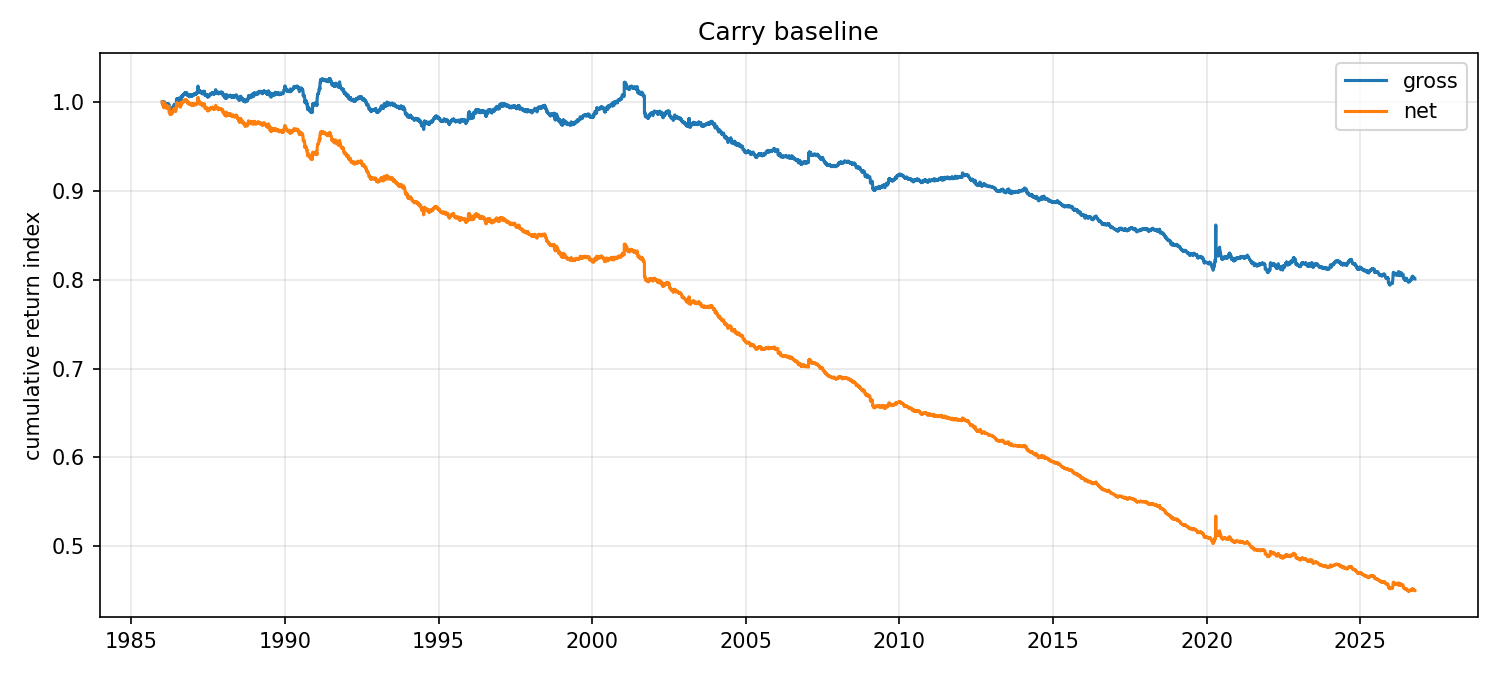

In [10]:
path = metrics.plot_result(full, "output/carry_cumulative.png")
display(Image(filename=str(path)))


## 9. 读这个 baseline

这是**负结果**：A 的 time-series sign 在这个 K=5 baseline 里没有 edge。

- Full sample net Sharpe 为负；成本把 gross 的弱负收益进一步拖低。
- `target_negative`（contango）的 **raw** forward mean 是正的，而且 train 里显著：
  意味着 contango 的 spread 平均会变好（更不负），所以 short spread 是错的方向。
- `target_positive`（backwardation）的 raw mean 接近 0，long spread 也没有补偿。
- 成本拖累约 1.4%/年，turnover 约 13x/年。

**这不是最终结论。** 这个 baseline 只检验了最简单的 A spec：
K=5、no liquidity filter、equal weight、weekly、5 bps、settlement fill。
它说明：如果 A 有 edge，不在这个最粗的版本里。


## 10. 下一步

- C（mean reversion）：复用同一个 engine，只换 signal。
- A 的变体：annualized carry threshold、cross-section、inverse-vol、h=21。
- Robustness：D=5/20、liquidity buckets、tick-based cost、point-in-time D=10 proxy。
- 报告里保留负结果，不要用 test 调参。
